# Lab 4: An LLM Extraction You Can Trust

---

## What this lab is

In Lab 3 you built emissions numbers from plant-level data. Many numbers a climate-finance team needs only exist as **text** in sustainability reports, so analysts increasingly use an LLM to turn report text into a table.

This lab treats the LLM as a **measurement instrument**, exactly like the utilisation rates and emission factors of Lab 3: it has an error rate, the error rate has an **interval**, some errors are random and some are **systematic**, and a risk committee needs to know which is which.

* **Part A. From text to table.** Define a schema, parse LLM output, and label a few excerpts yourself.
* **Part B. Measure the instrument.** Accuracy per field, an interval on accuracy, and what errors do to a sector total.
* **Part C. Self-consistency.** Ask the model 5 times. Does disagreement tell you where it is wrong?
* **Part D. Retrieval.** A mini-RAG: can we even find the right paragraph?
* **Part E. Communicate.** Should the bank adopt this pipeline?

## Learning goals

1. Turn free text into **validated structured data** (JSON + pydantic).
2. Evaluate an LLM against a **gold standard** and put an **interval** on its accuracy.
3. Distinguish **random** LLM errors (caught by resampling) from **systematic** ones (not caught).
4. Design a **human-review policy** from an uncertainty signal and a cost.
5. Explain why **retrieval** is a separate source of error in RAG.

## Conventions

* Questions are **[QUAL]** (2-4 sentences) or **[QUANT]** (a number from your code plus one sentence).
* Write each answer in the cell right under the question.
* Units: emissions in **tCO2e** (tonnes), production in **Mt** (million tonnes) of crude steel.
* Boxes marked **[OPTIONAL]** can be skipped.
* Run **Kernel -> Restart & Run All** before submitting.

## About the data

All 20 companies are **fictional**, but the excerpts copy the way real reports are written (different units, fiscal years, combined scopes, missing values). `recorded_responses.json` contains LLM answers **recorded in advance** (1 answer at temperature 0 and 5 answers at temperature 0.7 per excerpt) so that everyone works on the same outputs and no API key is needed. If you have access to an LLM, the optional box in A2 lets you run your own and compare.

## Submission

Work in **groups of up to 4**. Fill in every member before submitting.

1. Full name: Gabriel Destal  Student ID: B00821539
2. Full name: Georg Riekhakainen  Student ID: B00818730
3. Full name: Raphaël Hazan  Student ID: B00820995
4. Full name: Capucine Gros  Student ID: B00822768

**Group / repo name:** `aidams-lab4-destal-riekhakainen-hazan-gros`
**Submitter (one person):** Gabriel Destal
**Repo URL:** https://github.com/GabDestal/aidams-lab4-destal-riekhakainen-hazan-gros

### What to submit

- This notebook (`lab4.ipynb`) with all tasks completed and cells run (outputs visible)
- A short `README.md` with how to run the notebook

Create a GitHub repo, push the notebook and README, invite the instructor, and paste the **repo URL** above.

**Send submission info to my email (1 email per group).** Include the GitHub repo URL.

**Done when:** all names are filled in and the notebook contains outputs (no need for the instructor to re-run it).

## Setup (given)

In [1]:
import json, re
from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pydantic import BaseModel, ValidationError

pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

DATA = Path("data")
excerpts = pd.DataFrame(json.loads((DATA / "excerpts.json").read_text()))
gold = (pd.DataFrame(json.loads((DATA / "gold_labels.json").read_text())).set_index("id")
          .astype({"report_year": "Int64", "net_zero_year": "Int64"}))
recorded = pd.DataFrame(json.loads((DATA / "recorded_responses.json").read_text()))
corpus = json.loads((DATA / "aurelia_report_chunks.json").read_text())

FIELDS = ["company", "report_year", "scope1_tco2", "scope2_tco2", "production_mt", "net_zero_year"]
SEED = 42
print(excerpts.shape, gold.shape, recorded.shape, recorded.kind.value_counts().to_dict())

(20, 2) (20, 6) (120, 6) {'sample': 100, 'greedy': 20}


### The prompt and the LLM connection (given)

`ask_llm(prompt, temperature)` returns the model's raw text. With `BACKEND = "recorded"` (default) you do not need it: the answers are already in `recorded`. The other backends are there for the optional live run.

In [2]:
PROMPT = """You extract climate data from a steel company's report excerpt.
Return ONLY a JSON object with these keys:
  company        (string)
  report_year    (integer, the year the figures refer to; for a fiscal year use the calendar year it starts in)
  scope1_tco2    (number in tonnes CO2e, or null if not reported separately)
  scope2_tco2    (number in tonnes CO2e, market-based if both are given, or null if not reported separately)
  production_mt  (crude steel production in million metric tonnes, or null)
  net_zero_year  (integer year of a net zero / carbon neutrality target, or null if there is none)
  confidence     (number between 0 and 1: how confident you are that every field is correct)
Convert all units. Never compute a value that is not reported.

Excerpt:
{text}
"""

BACKEND = "recorded"          # "recorded" | "anthropic" | "openai" | "ollama"
MODEL = None                  # e.g. "claude-haiku-5-5" (anthropic), your course model (openai), "llama3.2" (ollama)


def ask_llm(prompt: str, temperature: float = 0.0) -> str:
    if BACKEND == "anthropic":
        import anthropic                                   # pip install anthropic; needs ANTHROPIC_API_KEY
        msg = anthropic.Anthropic().messages.create(
            model=MODEL, max_tokens=400, temperature=temperature,
            messages=[{"role": "user", "content": prompt}])
        return msg.content[0].text
    if BACKEND == "openai":
        from openai import OpenAI                          # pip install openai; needs OPENAI_API_KEY
        r = OpenAI().chat.completions.create(
            model=MODEL, temperature=temperature,
            messages=[{"role": "user", "content": prompt}])
        return r.choices[0].message.content
    if BACKEND == "ollama":
        import requests                                    # needs a local `ollama serve`
        r = requests.post("http://localhost:11434/api/generate", timeout=120, json={
            "model": MODEL, "prompt": prompt, "stream": False, "options": {"temperature": temperature}})
        return r.json()["response"]
    raise RuntimeError("BACKEND is 'recorded': use the `recorded` table instead of calling the model.")


print(PROMPT.format(text=excerpts.text[0]))

You extract climate data from a steel company's report excerpt.
Return ONLY a JSON object with these keys:
  company        (string)
  report_year    (integer, the year the figures refer to; for a fiscal year use the calendar year it starts in)
  scope1_tco2    (number in tonnes CO2e, or null if not reported separately)
  scope2_tco2    (number in tonnes CO2e, market-based if both are given, or null if not reported separately)
  production_mt  (crude steel production in million metric tonnes, or null)
  net_zero_year  (integer year of a net zero / carbon neutrality target, or null if there is none)
  confidence     (number between 0 and 1: how confident you are that every field is correct)
Convert all units. Never compute a value that is not reported.

Excerpt:
Aurelia Steel - Annual Climate Report 2024. In 2024 Aurelia Steel produced 12.6 million tonnes of crude steel across its three integrated sites. Gross Scope 1 emissions were 24,190,000 tCO2e, and Scope 2 emissions (market-based)

---
# PART A. From text to table

## A0. Be the annotator first

> **Pause & think.** No code. Do this **before** you look at `gold`.

### Q1 [QUAL] Label three excerpts yourself

Print the excerpts **E03**, **E09** and **E19** and fill in the six fields for each by hand, following the rules in `PROMPT`. Then compare with `gold.loc[["E03", "E09", "E19"]]`. Which field was hardest for you, and why? If two people in your group disagreed, what does that say about the "truth" we will score the LLM against?

In [3]:
ex = excerpts.set_index("id").text
for eid in ["E03", "E09", "E19"]:
    print(eid, ex[eid], "\n")

ours = pd.DataFrame({
    "E03": ["Lianhe Iron & Steel Group", 2023, 41_080_000, 5_120_000, 21.4, 2060],
    "E09": ["Ostend Metals", 2024, None, None, 4.4, 2050],
    "E19": ["Bluewater Iron", 2024, 5_100_000, 410_000, 3.3 * 0.907185, 2050],  # 1 short ton = 0.907185 t
}, index=FIELDS).T
pd.concat({"ours": ours, "gold": gold.loc[["E03", "E09", "E19"]]}, axis=1).swaplevel(axis=1).sort_index(axis=1)

E03 Lianhe Iron & Steel Group - Environmental, Social and Governance Report 2023. In 2023 the Group produced 21.4 million tonnes of crude steel. Greenhouse gas emissions (unit: 10,000 tonnes CO2): direct emissions (Scope 1) 4,108; indirect emissions from purchased electricity (Scope 2) 512. The Group will strive to peak carbon emissions before 2030 and achieve carbon neutrality by 2060. 

E09 Ostend Metals NV - Sustainability Statement 2024 (ESRS E1). Crude steel production: 4.4 Mt. Combined Scope 1 and Scope 2 emissions amounted to 8.7 MtCO2e, a 4% decrease year on year. Ostend Metals is committed to net zero emissions by 2050. 

E19 Bluewater Iron Corp. - 2024 Environmental Report. Shipments and production: we produced 3.3 million short tons of raw steel at our DRI-EAF facilities. Scope 1 emissions: 5.1 million metric tonnes CO2e; Scope 2: 410,000 metric tonnes CO2e. Bluewater targets net zero by 2050. 



company                            net_zero_year        \
                          gold                       ours          gold  ours   
E03  Lianhe Iron & Steel Group  Lianhe Iron & Steel Group          2060  2060   
E09              Ostend Metals              Ostend Metals          2050  2050   
E19             Bluewater Iron             Bluewater Iron          2050  2050   

    production_mt        report_year          scope1_tco2            \
             gold   ours        gold  ours           gold      ours   
E03        21.400 21.400        2023  2023 41,080,000.000  41080000   
E09         4.400  4.400        2024  2024            NaN      None   
E19         2.990  2.994        2024  2024  5,100,000.000   5100000   

      scope2_tco2           
             gold     ours  
E03 5,120,000.000  5120000  
E09           NaN     None  
E19   410,000.000   410000

**Your answer (Q1):**

Our labels match gold on all 18 fields (E19 production 3.3 short tons x 0.907 = 2.99 Mt, within rounding). The hardest field was **production for E19**: you have to notice "short tons" and convert, and the excerpt mixes short tons for steel with metric tonnes for CO2. E03's "unit: 10,000 tonnes" header and E09's combined Scope 1+2 (which must become `null`, not 8.7 Mt) also need a careful reading of the rules. If two annotators disagree, the "truth" itself carries label noise: gold is a convention defined by the prompt rules, so part of any measured LLM error may be ambiguity in the task rather than a model mistake.

## A1. A schema and a parser

**Goal.** Create

* a pydantic model `SteelDisclosure` with the six fields of the prompt plus `confidence` (types: `str`, `int`, `Optional[float]`, `Optional[int]` as appropriate);
* a function `parse_response(raw)` that finds the JSON object inside the raw text, validates it with `SteelDisclosure`, and returns `(record, None)` on success or `(None, error_message)` on failure;
* a DataFrame `pred` with one row per **successfully parsed** response (columns `id`, `kind`, `sample` and the fields) and a list `failures`.

> **Hint.** Models often wrap JSON in text or code fences: `re.search(r"\{.*\}", raw, flags=re.S)`. Then `SteelDisclosure.model_validate_json(...)` and `record.model_dump()`. Catch `ValidationError`.

In [4]:
class SteelDisclosure(BaseModel):
    company: str
    report_year: int
    scope1_tco2: Optional[float] = None
    scope2_tco2: Optional[float] = None
    production_mt: Optional[float] = None
    net_zero_year: Optional[int] = None
    confidence: Optional[float] = None


def parse_response(raw: str):
    m = re.search(r"\{.*\}", raw, flags=re.S)  # tolerate text or code fences around the JSON
    if m is None:
        return None, "no JSON object found"
    try:
        return SteelDisclosure.model_validate_json(m.group(0)), None
    except ValidationError as e:
        return None, "; ".join(f"{err['loc'][0]}: {err['msg']}" for err in e.errors())


rows, failures = [], []
for r in recorded.itertuples():
    rec, err = parse_response(r.raw_text)
    if rec is None:
        failures.append({"id": r.id, "kind": r.kind, "sample": r.sample, "error": err, "raw_text": r.raw_text})
    else:
        rows.append({"id": r.id, "kind": r.kind, "sample": r.sample, **rec.model_dump()})

pred = pd.DataFrame(rows)
print(pred.shape, "parsed,", len(failures), "failed")
pred.head()

(119, 10) parsed, 1 failed


,id,kind,sample,company,report_year,scope1_tco2,scope2_tco2,production_mt,net_zero_year,confidence
0,E01,greedy,0,Aurelia Steel,2024,"24,190,000.000","1,310,000.000",12.600,"2,050.000",0.910
1,E01,sample,0,Aurelia Steel,2024,"24,190,000.000","1,310,000.000",12.600,"2,050.000",0.940
2,E01,sample,1,Aurelia Steel,2024,"24,190,000.000","1,310,000.000",12.600,"2,050.000",0.910
3,E01,sample,2,Aurelia Steel,2024,"24,190,000.000","1,310,000.000",12.600,"2,050.000",0.930
4,E01,sample,3,Aurelia Steel,2024,"24,190,000.000","1,310,000.000",12.600,"2,050.000",0.960


### Q2 [QUANT + QUAL] What breaks?

(a) How many of the 120 recorded responses fail to parse, and why (look at their `raw_text`)? How many responses needed the regex because they were wrapped in text? (b) Give **two** options for handling a failed response in a production pipeline, and one risk of each. In Part B we will count a failed response as **wrong on every field**: why is that the honest choice for an accuracy figure?

In [5]:
print(f"Failed: {len(failures)} / {len(recorded)}")
for f in failures:
    print(f"  {f['id']} {f['kind']} #{f['sample']}: {f['error']}")

wrapped = ~recorded.raw_text.str.lstrip().str.startswith("{")
print(f"\nWrapped in text / code fences (needed the regex): {wrapped.sum()}")
recorded.loc[wrapped, ["id", "kind", "sample"]]

Failed: 1 / 120
  E11 greedy #0: production_mt: Input should be a valid number, unable to parse string as a number

Wrapped in text / code fences (needed the regex): 7


,id,kind,sample
11,E02,sample,4
18,E04,greedy,0
38,E07,sample,1
50,E09,sample,1
57,E10,sample,2
82,E14,sample,3
100,E17,sample,3


**Your answer (Q2):**

(a) **1 / 120** responses fails to parse: E11 greedy returns `"production_mt": "8.1 Mt"`, a string with a unit that pydantic cannot turn into a float. **7** responses were wrapped in "Sure! Here is the extracted data:" plus a code fence and only parsed thanks to the regex. Note that validation is not a plausibility check: years like `2214.0`, `20500.0` and `205.0` pass because pydantic coerces whole floats to `int`.

(b) Option 1: **retry** the call (possibly with the error message fed back). Risk: the retry can return a different, plausible but wrong answer, and it adds cost/latency. Option 2: **route to a human** (or leave the record empty and flag it). Risk: review cost, and if flagged records are silently dropped the database becomes biased toward "easy" reports. Counting a failure as wrong on every field is honest because in production that excerpt yields **no usable data**; dropping it would score the model only on the responses it handled well and inflate accuracy.

> ### [OPTIONAL] A2. Run your own model
>
> If you have an LLM available, set `BACKEND` and `MODEL` above, run your model on **E03, E09, E19** with `temperature=0`, parse the outputs with `parse_response` and compare them with the recorded greedy answers and with `gold`. Did your model make the same mistakes?

In [6]:
# your code here (optional)

---
# PART B. Measure the instrument

## B1. Accuracy per field

**Goal.** Create

* `field_correct(field, pred_value, gold_value)`: True if both are missing; False if only one is missing; for `company` a case- and punctuation-insensitive containment match; for years an exact match; for numbers a **relative tolerance of 2%**;
* `score(df)`: one row per (excerpt, field) with `id`, `field`, `pred`, `gold`, `correct`. Excerpts whose response failed to parse must appear with `correct = False` on every field;
* `greedy_scores = score(...)` for the **greedy** (temperature 0) answers, and a table of accuracy per field.

> **Hint.** Missing values come back as `None` or `NaN`: test with `pd.isna`. To include the failures, reindex the greedy predictions on `gold.index`.

In [7]:
def _norm(s):
    return re.sub(r"\W+", " ", str(s).lower()).strip()


def field_correct(field, pred_value, gold_value):
    if pd.isna(pred_value) and pd.isna(gold_value):
        return True
    if pd.isna(pred_value) or pd.isna(gold_value):
        return False
    if field == "company":
        p, g = _norm(pred_value), _norm(gold_value)
        return p in g or g in p
    if field in ("report_year", "net_zero_year"):
        return int(pred_value) == int(gold_value)
    return abs(float(pred_value) - float(gold_value)) <= 0.02 * abs(float(gold_value))


def score(df):
    df = df.set_index("id").reindex(gold.index)
    rows = []
    for eid, p in df.iterrows():
        parsed = pd.notna(p["company"])  # company is required, so NaN means the response failed to parse
        for f in FIELDS:
            g = gold.at[eid, f]
            rows.append({"id": eid, "field": f, "pred": p[f], "gold": g,
                         "correct": parsed and field_correct(f, p[f], g)})
    return pd.DataFrame(rows)


greedy_scores = score(pred[pred.kind == "greedy"])
acc_by_field = greedy_scores.groupby("field").correct.agg(accuracy="mean", n_wrong=lambda c: (~c).sum()).reindex(FIELDS)
acc_by_field

,accuracy,n_wrong
field,,
company,0.950,1
report_year,0.900,2
scope1_tco2,0.750,5
scope2_tco2,0.850,3
production_mt,0.900,2
net_zero_year,0.850,3


### Q3 [QUANT + QUAL] Where and how does it fail?

(a) Give the overall accuracy and the **worst field**. (b) Print every wrong (excerpt, field) with `pred` and `gold`, read the excerpt, and sort the errors into **error types** (e.g. unit conversion, wrong year in a table, wrong scope, a value invented for a missing field, parse failure). Which type is most frequent? (c) Which of these errors would **you** also have been likely to make in Q1?

In [8]:
print(f"Overall accuracy: {greedy_scores.correct.mean():.3f}  ({greedy_scores.correct.sum()}/{len(greedy_scores)})")
print(f"Worst field: {acc_by_field.accuracy.idxmin()} ({acc_by_field.accuracy.min():.2f})\n")

wrong = greedy_scores[~greedy_scores.correct].copy()
error_type = {
    ("E03", "scope1_tco2"): "unit conversion", ("E03", "scope2_tco2"): "unit conversion",
    ("E05", "scope1_tco2"): "invented value", ("E07", "scope1_tco2"): "wrong year in table",
    ("E08", "report_year"): "fiscal year", ("E09", "scope1_tco2"): "wrong scope (combined)",
    ("E10", "net_zero_year"): "invented value", ("E18", "scope2_tco2"): "invented value",
    ("E19", "production_mt"): "unit conversion", ("E20", "net_zero_year"): "invented value",
}
wrong["error_type"] = [error_type.get((i, f), "parse failure") for i, f in zip(wrong.id, wrong.field)]
display(wrong)
wrong.error_type.value_counts()

Overall accuracy: 0.867  (104/120)
Worst field: scope1_tco2 (0.75)



,id,field,pred,gold,correct,error_type
14,E03,scope1_tco2,"4,108,000.000","41,080,000.000",False,unit conversion
15,E03,scope2_tco2,"512,000.000","5,120,000.000",False,unit conversion
26,E05,scope1_tco2,"42,042,000.000",NaN,False,invented value
38,E07,scope1_tco2,"14,200,000.000","13,800,000.000",False,wrong year in table
43,E08,report_year,"2,025.000",2024,False,fiscal year
50,E09,scope1_tco2,"8,700,000.000",NaN,False,wrong scope (combined)
59,E10,net_zero_year,"2,030.000",<NA>,False,invented value
60,E11,company,NaN,Anatolia Celik,False,parse failure
61,E11,report_year,NaN,2024,False,parse failure
62,E11,scope1_tco2,NaN,"4,120,000.000",False,parse failure


error_type
parse failure             6
invented value            4
unit conversion           3
wrong year in table       1
fiscal year               1
wrong scope (combined)    1
Name: count, dtype: int64

**Your answer (Q3):**

(a) Overall greedy accuracy is **104/120 = 86.7%**; the worst field is **`scope1_tco2` (75%, 5 errors)**.

(b) Error types: **parse failure** (E11, 6 fields), **invented value for a missing field** (4: E05 Scope 1 computed from intensity x production, E10 net zero = the 2030 intensity target, E18 Scope 2 = 0 instead of null, E20 net zero = 2026 plant start), **unit conversion** (3: E03 Scope 1 and 2 off by 10x, E19 short tons), **wrong year in a table** (E07 picks 2023), **fiscal year** (E08 gives 2025 instead of 2024) and **wrong scope** (E09 puts the combined S1+S2 into Scope 1). Ignoring the single parse failure, the most frequent type is the **invented value**: the model fills a field that should be `null`.

(c) We would most likely have made the **unit-conversion** errors (E19 short tons, E03's 10,000-tonne unit) and possibly the **fiscal-year** rule for E08, since these require reading a small detail; the invented values are much less human (a human rarely writes 0 for "not disclosed").

## B2. An interval on accuracy

"91% accurate" on 120 fields is an **estimate** from a small sample, just like the utilisation rate in Lab 3. Two ways to put a range on it:

1. **Bayesian (Beta-Binomial).** With a uniform prior Beta(1, 1) and *k* correct out of *n*, the posterior is **Beta(1 + k, 1 + n - k)**. Its 5th and 95th percentiles give a 90% credible interval.
2. **Bootstrap over excerpts.** Resample **excerpts** (not fields) with replacement, recompute accuracy, repeat 2,000 times, take the 5th and 95th percentiles.

**Goal.** Create `k`, `n`, `beta_ci` and `boot_ci` (both 90%).

> **Hint.** `stats.beta(a, b).ppf([0.05, 0.95])`. For the bootstrap, first compute per excerpt the number correct and the number of fields (`groupby("id").correct.agg(["sum", "count"])`), then use the same `rng.integers(...)` trick as Lab 3.

accuracy = 104/120 = 0.867
Beta 90% CI:      [0.806, 0.908]  width 0.102
Bootstrap 90% CI: [0.775, 0.933]  width 0.158
P(accuracy >= 0.95 | data) = 0.0001


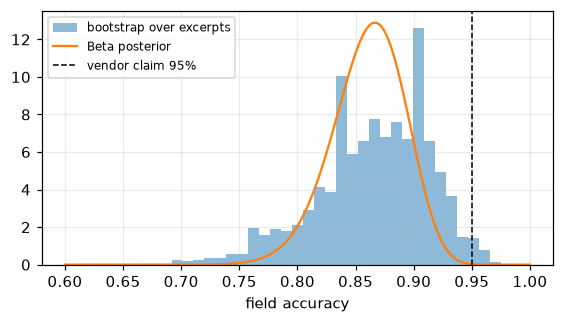

In [9]:
k, n = int(greedy_scores.correct.sum()), len(greedy_scores)
beta_ci = stats.beta(1 + k, 1 + n - k).ppf([0.05, 0.95])

per_ex = greedy_scores.groupby("id").correct.agg(["sum", "count"])
rng = np.random.default_rng(SEED)
idx = rng.integers(0, len(per_ex), size=(2000, len(per_ex)))  # resample whole excerpts, not fields
boot = per_ex["sum"].to_numpy()[idx].sum(1) / per_ex["count"].to_numpy()[idx].sum(1)
boot_ci = np.percentile(boot, [5, 95])

print(f"accuracy = {k}/{n} = {k / n:.3f}")
print(f"Beta 90% CI:      [{beta_ci[0]:.3f}, {beta_ci[1]:.3f}]  width {np.ptp(beta_ci):.3f}")
print(f"Bootstrap 90% CI: [{boot_ci[0]:.3f}, {boot_ci[1]:.3f}]  width {np.ptp(boot_ci):.3f}")
print(f"P(accuracy >= 0.95 | data) = {stats.beta(1 + k, 1 + n - k).sf(0.95):.4f}")

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(boot, bins=30, density=True, alpha=0.5, label="bootstrap over excerpts")
x = np.linspace(0.6, 1, 300)
ax.plot(x, stats.beta(1 + k, 1 + n - k).pdf(x), label="Beta posterior")
ax.axvline(0.95, color="k", ls="--", lw=1, label="vendor claim 95%")
ax.set_xlabel("field accuracy"); ax.legend(fontsize=8)
plt.show()

### Q4 [QUANT + QUAL] How sure are we about "accurate"?

(a) Report both intervals. Which is wider, and why? (Hint: are the six fields of one excerpt independent draws? Think of E11.) (b) Roughly how many excerpts would you need to label to **halve** the width of the interval? (c) A vendor advertises "95% extraction accuracy". Is your result consistent with that claim?

**Your answer (Q4):**

(a) Beta-Binomial 90% interval: **[0.806, 0.908]**; bootstrap over excerpts: **[0.775, 0.933]**. The bootstrap is wider because the six fields of an excerpt are **not independent**: errors cluster by excerpt (E11 loses all 6 at once, E03 two), so the effective sample size is closer to 20 excerpts than to 120 fields, and the Beta interval, which assumes 120 independent draws, is too narrow.

(b) Interval width scales like 1/sqrt(n), so halving it needs about **4x as many excerpts, i.e. ~80 labelled excerpts** (~60 more).

(c) **No.** 95% lies above both upper bounds (0.908 and 0.933), and the posterior probability that accuracy is at least 95% is about 0.0001. On these reports the greedy pipeline is very unlikely to reach the vendor's figure.

## B3. What do the errors do downstream?

A lender wants the **sector total of Scope 1 emissions** and the **median emission intensity** (tCO2 per tonne of steel) of these 20 companies.

**Goal.** Create a DataFrame `downstream` indexed by excerpt with `scope1_llm`, `scope1_gold`, `error_t` (= LLM - gold, in tCO2, treating a missing value as 0 for the total) and print: total Scope 1 according to the LLM and to gold (MtCO2), the **net** and the **absolute** error, and the median intensity (Scope 1 / production, only where both are present) for LLM and gold.

In [10]:
g_pred = pred[pred.kind == "greedy"].set_index("id").reindex(gold.index)
downstream = pd.DataFrame({"scope1_llm": g_pred.scope1_tco2, "scope1_gold": gold.scope1_tco2.astype(float)})
downstream["error_t"] = downstream.scope1_llm.fillna(0) - downstream.scope1_gold.fillna(0)

tot_llm, tot_gold = downstream.scope1_llm.sum() / 1e6, downstream.scope1_gold.sum() / 1e6
print(f"Sector Scope 1  LLM: {tot_llm:,.2f} MtCO2   gold: {tot_gold:,.2f} MtCO2")
print(f"Net error: {downstream.error_t.sum() / 1e6:+,.2f} MtCO2   absolute error: {downstream.error_t.abs().sum() / 1e6:,.2f} MtCO2")

# intensity in tCO2 per tonne: Scope 1 (t) / production (Mt * 1e6)
int_llm = (g_pred.scope1_tco2 / (g_pred.production_mt * 1e6)).dropna()
int_gold = (gold.scope1_tco2.astype(float) / (gold.production_mt * 1e6)).dropna()
print(f"Median intensity  LLM: {int_llm.median():.3f} tCO2/t (n={len(int_llm)})   gold: {int_gold.median():.3f} tCO2/t (n={len(int_gold)})")

downstream[downstream.error_t != 0].sort_values("error_t", key=abs, ascending=False)

Sector Scope 1  LLM: 252.11 MtCO2   gold: 242.06 MtCO2
Net error: +10.05 MtCO2   absolute error: 92.23 MtCO2
Median intensity  LLM: 1.895 tCO2/t (n=18)   gold: 1.865 tCO2/t (n=17)


,scope1_llm,scope1_gold,error_t
id,,,
E05,"42,042,000.000",NaN,"42,042,000.000"
E03,"4,108,000.000","41,080,000.000","-36,972,000.000"
E09,"8,700,000.000",NaN,"8,700,000.000"
E11,NaN,"4,120,000.000","-4,120,000.000"
E07,"14,200,000.000","13,800,000.000","400,000.000"


### Q5 [QUANT + QUAL] Accuracy is a mean, the damage is in the tail

(a) Report the net and absolute error on the sector total. Which **two** excerpts contribute most? (b) Why can a 90% field accuracy hide a large error on a portfolio total, while the **median** intensity barely moves? Connect to Session 4 ("the mean hides the tail"). (c) What would you report to the lender alongside the total?

**Your answer (Q5):**

(a) The LLM total is 252.1 MtCO2 vs 242.1 MtCO2 in gold: a **net error of +10.1 MtCO2 (+4%)** but an **absolute error of 92.2 MtCO2 (~38% of the total)**. The two largest contributors are **E05 (+42.0 Mt**, a Scope 1 value invented from intensity x production) and **E03 (-37.0 Mt**, a 10x unit error); they largely cancel, which makes the net figure look misleadingly good.

(b) Field accuracy counts every error equally, but the total weights errors by their **size**: one 10x unit slip on a large emitter or one invented value dominates the sum. The median only depends on the middle of the distribution, so a few extreme values (E03's absurdly low intensity) barely move it (1.895 vs 1.865 tCO2/t). As in Session 4, the mean/total is driven by the tail, and an average accuracy says nothing about how heavy that tail is.

(c) Report the total **with an uncertainty range** and the absolute (not only net) error from the validation sample, list which companies were imputed, missing or flagged, and show the contribution of the largest emitters, with their values verified by a human.

---
# PART C. Self-consistency: ask five times

At temperature 0.7 the model **samples** its answer, so asking the same question five times can give different answers. Idea: use the **majority vote** as the answer and the **agreement** (share of samples that agree with the vote) as an uncertainty signal. This is an **ensemble**, like the multi-model comparison of Session 4.

## C1. Vote and agreement

**Goal.** Create `votes`: one row per (excerpt, field) with `vote` (most frequent answer among the 5 samples, missing counted as an answer), `agreement` (count of the vote / 5) and `correct`. Compare the vote's accuracy with the greedy accuracy, and show the accuracy for agreement **5/5**, **4/5** and **3/5 or less**.

> **Hint.** To count values that may be `None`, `NaN` or numbers, turn each into a string key first: `json.dumps(None if pd.isna(v) else v)`.

In [11]:
samples = pred[pred.kind == "sample"]


def key(v):
    return json.dumps(None if pd.isna(v) else v)


rows = []
for eid, grp in samples.groupby("id"):
    for f in FIELDS:
        counts = grp[f].map(key).value_counts()
        vote = json.loads(counts.index[0])
        rows.append({"id": eid, "field": f, "vote": vote, "agreement": counts.iloc[0] / 5,
                     "correct": field_correct(f, vote, gold.at[eid, f])})
votes = pd.DataFrame(rows)

votes["bin"] = pd.cut(votes.agreement, [0, 0.6, 0.8, 1], labels=["<=3/5", "4/5", "5/5"])
print(f"Greedy accuracy: {greedy_scores.correct.mean():.3f}   Vote accuracy: {votes.correct.mean():.3f}")
votes.groupby("bin", observed=True).correct.agg(n="count", n_correct="sum", accuracy="mean")

Greedy accuracy: 0.867   Vote accuracy: 0.950


,n,n_correct,accuracy
bin,,,
<=3/5,12,9,0.750
4/5,15,14,0.933
5/5,93,91,0.978


### Q6 [QUANT + QUAL] Is disagreement a useful signal?

(a) Report the greedy and vote accuracies and the accuracy in each agreement bin. (b) Is low agreement a good warning sign? (c) Compute the accuracy for 5/5 with a Beta(1,1) 90% interval: can you claim it is above 95%?

In [12]:
full = votes[votes.bin == "5/5"]
k5, n5 = int(full.correct.sum()), len(full)
post5 = stats.beta(1 + k5, 1 + n5 - k5)
lo, hi = post5.ppf([0.05, 0.95])
print(f"5/5 accuracy: {k5}/{n5} = {k5 / n5:.3f}   90% CI [{lo:.3f}, {hi:.3f}]   P(acc > 0.95) = {post5.sf(0.95):.3f}")

low = votes[votes.bin != "5/5"]
print(f"Below 5/5: {len(low)} fields, {(~low.correct).sum()} wrong ({(~low.correct).mean():.0%} error rate)")

5/5 accuracy: 91/93 = 0.978   90% CI [0.935, 0.991]   P(acc > 0.95) = 0.855
Below 5/5: 27 fields, 4 wrong (15% error rate)


**Your answer (Q6):**

(a) Greedy accuracy **86.7%**, majority-vote accuracy **95.0%**. By agreement: **5/5: 97.8%** (91/93), **4/5: 93.3%** (14/15), **3/5 or less: 75%** (9/12).

(b) Yes, it is a **useful but imperfect** warning sign: accuracy falls steadily as agreement falls, and the 27 fields below 5/5 (22% of fields) contain 4 of the 6 errors (15% error rate vs 2% at 5/5). But agreement is not proof of correctness: 2 errors sit in the 5/5 bin.

(c) 5/5 accuracy is 91/93 = 97.8% with a 90% Beta interval of **[0.935, 0.991]**. The lower bound is below 95% (P(acc > 0.95) is about 0.86), so we **cannot claim** at 90% confidence that unanimous fields are above 95% accurate.

## C2. Confidently wrong

### Q7 [QUAL] The errors that resampling cannot see

Print the (excerpt, field) pairs where **all five samples agree** and the vote is **wrong**. Read the excerpts. (a) What do these errors have in common? (b) Using Session 4 vocabulary, why does asking the same model more times not reveal them? Which fix would (a different prompt, a second model, a unit-conversion rule, a human)? (c) Name the analogue in the Session 4 worked example.

In [13]:
confident_wrong = votes[(votes.agreement == 1) & ~votes.correct].copy()
confident_wrong["gold"] = [gold.at[i, f] for i, f in zip(confident_wrong.id, confident_wrong.field)]
display(confident_wrong[["id", "field", "vote", "gold", "agreement"]])

ex = excerpts.set_index("id").text
for eid in confident_wrong.id.unique():
    print(eid, ex[eid], "\n")

,id,field,vote,gold,agreement
14,E03,scope1_tco2,"4,108,000.000","41,080,000.000",1.000
112,E19,production_mt,3.300,2.990,1.000


E03 Lianhe Iron & Steel Group - Environmental, Social and Governance Report 2023. In 2023 the Group produced 21.4 million tonnes of crude steel. Greenhouse gas emissions (unit: 10,000 tonnes CO2): direct emissions (Scope 1) 4,108; indirect emissions from purchased electricity (Scope 2) 512. The Group will strive to peak carbon emissions before 2030 and achieve carbon neutrality by 2060. 

E19 Bluewater Iron Corp. - 2024 Environmental Report. Shipments and production: we produced 3.3 million short tons of raw steel at our DRI-EAF facilities. Scope 1 emissions: 5.1 million metric tonnes CO2e; Scope 2: 410,000 metric tonnes CO2e. Bluewater targets net zero by 2050. 



**Your answer (Q7):**

(a) Both confidently wrong fields are **unit conversions with an unusual unit**: E03's "unit: 10,000 tonnes CO2" (4,108 x 10,000 = 41.08 Mt, the model gives 4.108 Mt) and E19's "short tons" (3.3 short tons = 2.99 Mt, the model keeps 3.3). The model misreads the unit the same way every time.

(b) These are **systematic errors (bias)**, not random noise. Resampling the same model only averages away **variance**; the five samples share the same blind spot, so they are correlated and agree on the wrong answer. Fixes that bring **independent** information work: an explicit **unit-conversion rule** or a regex that flags non-standard units, a **second, different model**, or a **human**. A different prompt could help (e.g. asking to quote the unit first), but it is still the same model.

(c) The analogue is the Session 4 ensemble of models that **share the same structural bias**: agreement between members narrows the spread but not the bias, so the ensemble is confidently wrong and its spread underestimates true uncertainty.

## C3. The model's own confidence

Each response contains a `confidence` the model wrote about itself.

### Q8 [QUANT + QUAL] Is stated confidence calibrated?

For the **sample** responses, compute the mean stated confidence and the share of responses with **all six fields correct**. Then group responses by confidence (`pd.cut(..., [0, .90, .93, .96, 1])`) and show the share fully correct in each group. Is the model **over-confident**? Is its confidence still useful for **ranking** responses?

Mean stated confidence: 0.928   Share fully correct: 0.550


,n,mean_conf,share_correct
confidence,,,
"(0.0, 0.9]",21,0.890,0.286
"(0.9, 0.93]",35,0.921,0.457
"(0.93, 0.96]",38,0.947,0.737
"(0.96, 1.0]",6,0.978,0.833


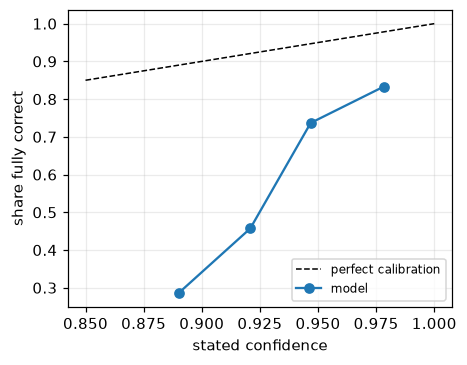

In [14]:
s = samples.copy()
s["all_correct"] = [all(field_correct(f, r[f], gold.at[r["id"], f]) for f in FIELDS) for _, r in s.iterrows()]
print(f"Mean stated confidence: {s.confidence.mean():.3f}   Share fully correct: {s.all_correct.mean():.3f}")

calib = s.groupby(pd.cut(s.confidence, [0, .90, .93, .96, 1]), observed=True).agg(
    n=("all_correct", "size"), mean_conf=("confidence", "mean"), share_correct=("all_correct", "mean"))
display(calib)

fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.plot([0.85, 1], [0.85, 1], "k--", lw=1, label="perfect calibration")
ax.plot(calib.mean_conf, calib.share_correct, "o-", label="model")
ax.set_xlabel("stated confidence"); ax.set_ylabel("share fully correct"); ax.legend(fontsize=8)
plt.show()

**Your answer (Q8):**

The mean stated confidence is **0.93**, but only **55%** of sample responses have all six fields correct, so the model is strongly **over-confident**: in every bin the share fully correct (29%, 46%, 74%, 83%) is far below the stated confidence (0.89, 0.92, 0.95, 0.98). Its confidence is still somewhat useful for **ranking**: the share correct rises monotonically with stated confidence, so low-confidence responses are good candidates for review. It should be used as an ordering, never read as a probability.

## C4. A review policy with a price tag

A human analyst can check a field for **EUR 4**. An error that reaches the lender's report costs on average **EUR 150** (restatement, analyst time, reputational risk). Three policies:

| Policy | Rule |
|---|---|
| **P0** | trust the majority vote everywhere |
| **P1** | send to a human every field with agreement **< 5/5** |
| **P2** | send to a human every field with agreement **<= 3/5** |

Assume the human fixes every field they review.

### Q9 [QUANT + QUAL] Which policy?

For each policy compute the number of fields reviewed, the number of errors that remain, and the total cost. Which policy is cheapest? Which errors survive even the best policy, and what one extra check would catch them?

In [15]:
COST_REVIEW, COST_ERROR = 4, 150
policies = {
    "P0": pd.Series(False, index=votes.index),
    "P1": votes.agreement < 1,
    "P2": votes.agreement <= 0.6,
}
policy_table = pd.DataFrame([
    {"policy": name, "reviewed": rev.sum(), "errors_left": (~votes.correct & ~rev).sum()}
    for name, rev in policies.items()
]).set_index("policy")
policy_table["cost_eur"] = COST_REVIEW * policy_table.reviewed + COST_ERROR * policy_table.errors_left
display(policy_table)

surviving = votes[~votes.correct & ~policies["P1"]]
surviving.assign(gold=[gold.at[i, f] for i, f in zip(surviving.id, surviving.field)])[["id", "field", "vote", "gold", "agreement"]]

,reviewed,errors_left,cost_eur
policy,,,
P0,0,6,900
P1,27,2,408
P2,12,3,498


,id,field,vote,gold,agreement
14,E03,scope1_tco2,"4,108,000.000","41,080,000.000",1.000
112,E19,production_mt,3.300,2.990,1.000


**Your answer (Q9):**

| Policy | Reviewed | Errors left | Cost |
|---|---|---|---|
| P0 | 0 | 6 | EUR 900 |
| P1 | 27 | 2 | **EUR 408** |
| P2 | 12 | 3 | EUR 498 |

**P1** (review everything below 5/5) is cheapest: reviewing 15 more fields than P2 costs EUR 60 but catches one more EUR 150 error. The errors that survive even P1 are the two **confidently wrong unit conversions** (E03 Scope 1, E19 production). One extra check would catch them: a deterministic **unit / plausibility rule** that sends to review any excerpt mentioning a non-standard unit ("10,000 tonnes", "short tons", "kt") or with an implausible intensity (E03's 0.19 tCO2/t is far below any blast-furnace producer).

---
# PART D. Retrieval: finding the right paragraph

Real reports are 100+ pages, longer than you want to send to a model. **RAG** first **retrieves** the most relevant chunks, then asks the LLM to answer from them. If retrieval misses, the LLM never sees the answer.

`corpus["chunks"]` is a (fictional) report cut into 16 chunks; `corpus["queries"]` are 6 questions with the index of the chunk that answers each one.

## D1. TF-IDF retrieval

**Goal.** Represent chunks and queries as **TF-IDF vectors** (`TfidfVectorizer(stop_words="english")`), score each chunk by **cosine similarity** with the query, and build a table `retrieval` with, per query, the top-3 chunk indices, whether the relevant chunk is **rank 1** (`hit@1`) and whether it is in the **top 3** (`hit@3`).

> **Hint.** `from sklearn.feature_extraction.text import TfidfVectorizer`, `from sklearn.metrics.pairwise import cosine_similarity`; `np.argsort(-scores)[:3]`.

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

chunks = corpus["chunks"]
queries = pd.DataFrame(corpus["queries"])

vec = TfidfVectorizer(stop_words="english").fit(chunks)
sims = cosine_similarity(vec.transform(queries["query"]), vec.transform(chunks))
top3 = np.argsort(-sims, axis=1)[:, :3]

retrieval = queries[["qid", "query"]].assign(
    relevant=queries.relevant.str[0],
    top3=[list(t) for t in top3],
    top1_score=sims.max(axis=1),
)
retrieval["hit@1"] = [rel == t[0] for rel, t in zip(retrieval.relevant, retrieval.top3)]
retrieval["hit@3"] = [rel in t for rel, t in zip(retrieval.relevant, retrieval.top3)]
retrieval

,qid,query,relevant,top3,top1_score,hit@1,hit@3
0,Q1,What were Scope 1 emissions in 2024?,3,"[1, 5, 12]",0.338,False,False
1,Q2,net zero target year,5,"[5, 0, 13]",0.366,True,True
2,Q3,crude steel production 2024,2,"[2, 3, 0]",0.347,True,True
3,Q4,investment in hydrogen DRI capex,6,"[6, 0, 2]",0.225,True,True
4,Q5,impact of the carbon price on EBITDA,8,"[8, 13, 7]",0.346,True,True
5,Q6,flooding exposure of our plants,9,"[3, 6, 1]",0.208,False,False


### Q10 [QUANT + QUAL] Why does retrieval miss?

(a) Report hit@1 and hit@3. (b) For each failed query, print the query, the chunk it retrieved first and the relevant chunk. Why did TF-IDF fail? (c) **Embeddings** (dense vectors from a neural model) compare meaning rather than words. Which failure would they most likely fix? (d) In a RAG pipeline, why is a retrieval miss more dangerous than an extraction error?

In [17]:
print(f"hit@1 = {retrieval['hit@1'].mean():.2f}   hit@3 = {retrieval['hit@3'].mean():.2f}\n")

for r in retrieval[~retrieval["hit@1"]].itertuples():
    print(f"{r.qid}: {r.query!r}  (top-1 score {r.top1_score:.2f})")
    print(f"  retrieved #{r.top3[0]}: {chunks[r.top3[0]]}")
    print(f"  relevant  #{r.relevant}: {chunks[r.relevant]}")
    shared = set(vec.build_analyzer()(r.query)) & set(vec.build_analyzer()(chunks[r.relevant]))
    print(f"  words shared with relevant chunk: {sorted(shared) or 'none'}\n")

hit@1 = 0.67   hit@3 = 0.67

Q1: 'What were Scope 1 emissions in 2024?'  (top-1 score 0.34)
  retrieved #1: About this report. Greenhouse gas reporting follows the GHG Protocol. Scope 1 covers emissions from sources we own or control, Scope 2 covers purchased electricity and heat, and Scope 3 covers our value chain.
  relevant  #3: Climate performance. Direct greenhouse gas emissions from our blast furnaces, coke ovens and sinter plants totalled 24.19 MtCO2e in 2024, an intensity of 1.92 tCO2e per tonne of crude steel.
  words shared with relevant chunk: ['2024', 'emissions']

Q6: 'flooding exposure of our plants'  (top-1 score 0.21)
  retrieved #3: Climate performance. Direct greenhouse gas emissions from our blast furnaces, coke ovens and sinter plants totalled 24.19 MtCO2e in 2024, an intensity of 1.92 tCO2e per tonne of crude steel.
  relevant  #9: Physical risk. Two of our three sites are located on major rivers. An assessment of riverine inundation under high-warming scenarios id

**Your answer (Q10):**

(a) **hit@1 = 0.67** and **hit@3 = 0.67** (4/6): when TF-IDF misses, it misses completely.

(b) **Q1** ("Scope 1 emissions in 2024") retrieves chunk 1, the methodology paragraph that *defines* Scope 1, because it shares the rare word "scope"; the relevant chunk never says "Scope 1", it says "direct greenhouse gas emissions". **Q6** ("flooding exposure of our plants") shares **no words** with the relevant chunk ("riverine inundation", "most exposed", "sites"); the only match is "plants" in "sinter plants". TF-IDF matches exact tokens: no synonyms, no stemming (exposure vs exposed), no notion that Scope 1 = direct emissions.

(c) Embeddings would most likely fix **Q6**, since "flooding" vs "inundation" and "plants" vs "sites" are near-synonyms in meaning. Q1 is harder because it requires domain knowledge that Scope 1 means direct emissions, and the definitional chunk is also semantically close.

(d) An extraction error can be caught downstream (resampling, a second model, a reviewer checking the excerpt). After a retrieval miss the LLM never sees the answer, so it either says "not reported" or, worse, **invents** a plausible value from the wrong chunk; the error is invisible to the reviewer, who only sees the retrieved text, and self-consistency will not flag it.

> ### [OPTIONAL] D2. Dense embeddings
>
> `pip install sentence-transformers`, then `SentenceTransformer("all-MiniLM-L6-v2").encode(...)` to embed chunks and queries, and redo D1 with cosine similarity on the embeddings. Does hit@1 improve? Which query still fails?

In [19]:
try:
    from sentence_transformers import SentenceTransformer
except ImportError:
    print("sentence-transformers not installed: `uv add sentence-transformers` to run this cell.")
else:
    emb = SentenceTransformer("all-MiniLM-L6-v2")
    dense_sims = cosine_similarity(emb.encode(queries["query"].tolist()), emb.encode(chunks))
    dense_top3 = np.argsort(-dense_sims, axis=1)[:, :3]
    dense = queries[["qid", "query"]].assign(relevant=queries.relevant.str[0], top3=[list(t) for t in dense_top3])
    dense["hit@1"] = [rel == t[0] for rel, t in zip(dense.relevant, dense.top3)]
    dense["hit@3"] = [rel in t for rel, t in zip(dense.relevant, dense.top3)]
    print(f"Dense hit@1 = {dense['hit@1'].mean():.2f}   hit@3 = {dense['hit@3'].mean():.2f}")
    display(dense)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 240.40it/s]


Dense hit@1 = 0.83   hit@3 = 0.83


,qid,query,relevant,top3,hit@1,hit@3
0,Q1,What were Scope 1 emissions in 2024?,3,"[5, 12, 1]",False,False
1,Q2,net zero target year,5,"[5, 0, 6]",True,True
2,Q3,crude steel production 2024,2,"[2, 0, 3]",True,True
3,Q4,investment in hydrogen DRI capex,6,"[6, 8, 7]",True,True
4,Q5,impact of the carbon price on EBITDA,8,"[8, 13, 7]",True,True
5,Q6,flooding exposure of our plants,9,"[9, 10, 3]",True,True


---
# PART E. Communicate

### Q11 [QUAL] Should the bank adopt this pipeline?

Write a note of **about 80 words** to the bank's **Head of ESG Data**, who must decide whether to use this LLM pipeline to build a database of steel-company emissions. Include: the **accuracy with its interval**, the **main failure mode**, your **recommended review policy** and its cost, and **one limitation** of this evaluation. Plain language, no jargon. Use a calibrated word from the IPCC scale at least once.

**Your answer (Q11):**

To the Head of ESG Data: On 20 test reports, the tool extracted 87% of figures correctly (likely between 78% and 93%), below the vendor's 95%. Its main weakness is unusual units and filling in figures the company never reported; single errors on two companies moved the sector total by about 40 Mt each. Asking the tool five times and having an analyst check every disagreement costs about EUR 4 per field and catches most errors. Limitation: only 20 fictional reports were tested, so add a unit-check rule and test more.